# RepairRadar — Complete Machine Learning + Streamlit Project

**AI-Based Predictive Maintenance and Machine Failure Prediction System**

This Google Colab notebook follows the project assignment in order: load your own synthetic CSV, inspect and prepare the data, explore it, train and compare machine-learning models, evaluate the selected models, save the models, and launch a working Streamlit application.

### What you will build

- **Task 1 — Failure prediction:** estimate whether a machine will experience a simulated failure within the next seven days.
- **Task 2 — Fault classification:** classify the machine's current condition as Normal, Bearing Wear, Misalignment, Overheating, or Imbalance.
- **Application:** a modern, interactive dashboard with a single horizontal header (no sidebar), readable light-mode charts, and a muted sage-green, dusty-rose, and warm-cream design.

> **Important:** This notebook expects the CSV generated for RepairRadar. It does not silently replace your dataset with downloaded data. The optional machine photos are supplied in a small companion ZIP, keeping this notebook lightweight.

### Before you run it

1. Open this notebook in **Google Colab**.
2. Run the cells from top to bottom.
3. When prompted, optionally upload `repairradar_images.zip` for the dashboard photos.
4. Upload `repairradar_synthetic.csv` when the dataset cell asks for it.
5. Wait for both models to train and for the model files to be saved.
6. Run the final launch cell to open the redesigned Streamlit app inside Colab. If an older app is still running, the launch cell stops it and starts the updated header-only version.

The code is kept in small, explained steps. You can also download the trained models and project files from Colab.

## Project workflow

1. **Setup:** install libraries and prepare the project folders.
2. **Images:** optionally upload the small companion image ZIP.
3. **Dataset:** upload and validate your generated CSV.
4. **EDA:** inspect records, target distributions, and sensor patterns.
5. **Split:** separate training, validation, and testing data by machine ID to reduce machine-level data leakage.
6. **Training:** compare four classification algorithms for each prediction task.
7. **Evaluation:** report accuracy, precision, recall, F1-score, and confusion matrices on the held-out test machines.
8. **Save:** save the selected models, dataset, metrics, and configuration.
9. **Streamlit:** launch the interactive RepairRadar dashboard.

## 1. Install the required libraries

We use common Python libraries. No paid API, GPU, or cloud deployment service is required.

In [1]:
%pip -q install --upgrade scikit-learn streamlit plotly joblib seaborn psutil

## 2. Import libraries and prepare folders

`pandas` handles the CSV, `scikit-learn` trains the models, `matplotlib` and `seaborn` create notebook charts, and `joblib` saves the trained models.

In [2]:
import os
import json
import time
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
import joblib
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROJECT_DIR = Path("/content/RepairRadar")
ARTIFACT_DIR = PROJECT_DIR / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Muted sage green + dusty rose + warm cream
SAGE = "#788B78"
DUSTY_ROSE = "#B87980"
WARM_CREAM = "#F7F3EA"
DARK_GREEN = "#26352C"
PALE_SAGE = "#E7EDE4"
PALE_ROSE = "#F3E3E3"

plt.rcParams.update({
    "figure.facecolor": WARM_CREAM,
    "axes.facecolor": "#FFFCF7",
    "axes.edgecolor": "#D8D1C6",
    "axes.labelcolor": DARK_GREEN,
    "text.color": DARK_GREEN,
    "xtick.color": DARK_GREEN,
    "ytick.color": DARK_GREEN,
    "axes.titleweight": "bold",
    "font.size": 10,
})

print("RepairRadar project folders are ready.")
print("Project folder:", PROJECT_DIR)

RepairRadar project folders are ready.
Project folder: /content/RepairRadar


## 3. Add the machine images (optional)

The two dashboard images are provided separately in `repairradar_images.zip`, so the notebook stays small and easy to read. Upload that ZIP when prompted. If you skip it, the Streamlit application still works; it will simply hide the optional photos.

In [3]:
from zipfile import ZipFile

image_files = [
    PROJECT_DIR / "repairradar_machine_banner.jpg",
    PROJECT_DIR / "repairradar_bearing_detail.jpg",
]

if not all(path.exists() for path in image_files):
    try:
        from google.colab import files
        print("Upload the companion repairradar_images.zip file (optional).")
        uploaded_images = files.upload()
        zip_names = [name for name in uploaded_images if name.lower().endswith(".zip")]

        if zip_names:
            with ZipFile(zip_names[0], "r") as image_zip:
                image_zip.extractall(PROJECT_DIR)
            print("Image files extracted into:", PROJECT_DIR)
        else:
            print("No image ZIP uploaded. The application will run without machine photos.")
    except ImportError:
        print("Image ZIP upload is available in Google Colab. Continuing without optional photos.")
else:
    print("Machine images are already available.")

for image_path in image_files:
    print(image_path.name, "—", "available" if image_path.exists() else "not uploaded")

Upload the companion repairradar_images.zip file (optional).


Saving repairradar_images.zip to repairradar_images.zip
Image files extracted into: /content/RepairRadar
repairradar_machine_banner.jpg — available
repairradar_bearing_detail.jpg — available


## 4. Upload your synthetic dataset

Upload the CSV generated for RepairRadar. The expected filename is `repairradar_synthetic.csv`. If the file is already in `/content`, the notebook will use it automatically.

In [4]:
DATA_PATH = Path("/content/repairradar_synthetic.csv")

if not DATA_PATH.exists():
    try:
        from google.colab import files
        print("Please upload your RepairRadar CSV file.")
        uploaded = files.upload()
        csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
        if not csv_files:
            raise FileNotFoundError("No CSV file was uploaded. Please upload repairradar_synthetic.csv.")

        selected_file = Path(csv_files[0])
        # Colab usually saves the uploaded file directly in /content. Only copy
        # it when the upload path is different from the target path.
        if selected_file.resolve() != DATA_PATH.resolve():
            shutil.copy2(selected_file, DATA_PATH)
    except ImportError:
        raise FileNotFoundError(
            "Place repairradar_synthetic.csv in /content before running this cell."
        )

# Read the generated dataset
df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully!")
print("File:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Please upload your RepairRadar CSV file.


Saving repairradar_synthetic.csv to repairradar_synthetic.csv
Dataset loaded successfully!
File: /content/repairradar_synthetic.csv
Shape: (15000, 13)


,machine_id,timestamp,vibration_rms_mm_s,operating_temperature_c,motor_current_a,rotational_speed_rpm,machine_load_pct,operating_hours,machine_age_years,hours_since_maintenance,lubrication_quality,failure_within_7_days,fault_type
0,MCH-001,2025-01-01 00:00:00,1.8846,54.3989,18.9253,3504.1217,78.5293,7029.6502,13.568,413.1226,3,0,Normal
1,MCH-001,2025-01-01 12:00:00,1.9338,53.5917,16.9355,3494.5062,75.1911,7040.3642,13.568,423.8367,3,0,Normal
2,MCH-001,2025-01-02 00:00:00,1.6349,55.4627,16.4836,3522.6313,75.7052,7048.5061,13.568,431.9786,3,0,Normal
3,MCH-001,2025-01-02 12:00:00,1.9521,53.5700,16.4119,3514.6828,73.7430,7059.4294,13.568,442.9018,3,0,Normal
4,MCH-001,2025-01-03 00:00:00,1.9013,54.1012,16.6620,3514.5393,74.5847,7068.3857,13.568,451.8581,3,0,Normal


## 5. Validate and prepare the dataset

The notebook checks that the important columns exist. `machine_id` and `timestamp` are metadata; they are not given to the model as input features. The input features are the machine sensor readings and operating conditions.

In [5]:
FEATURE_COLUMNS = [
    "vibration_rms_mm_s",
    "operating_temperature_c",
    "motor_current_a",
    "rotational_speed_rpm",
    "machine_load_pct",
    "operating_hours",
    "machine_age_years",
    "hours_since_maintenance",
    "lubrication_quality",
]

TARGET_FAILURE = "failure_within_7_days"
TARGET_FAULT = "fault_type"
REQUIRED_COLUMNS = FEATURE_COLUMNS + [TARGET_FAILURE, TARGET_FAULT]

missing_columns = [column for column in REQUIRED_COLUMNS if column not in df.columns]
if missing_columns:
    raise ValueError(
        "Your CSV is missing these required columns: " + ", ".join(missing_columns)
        + "\nCheck the column names in your dataset generator."
    )

# Convert sensor features to numbers. Missing sensor values can be handled by the model pipeline.
for column in FEATURE_COLUMNS:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Accept common binary label formats and convert them to 0 and 1.
def convert_failure_label(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (bool, np.bool_)):
        return int(value)
    text = str(value).strip().lower()
    mapping = {"yes": 1, "true": 1, "failure": 1, "fail": 1,
               "no": 0, "false": 0, "normal": 0, "pass": 0}
    if text in mapping:
        return mapping[text]
    try:
        number = int(float(text))
        if number in (0, 1):
            return number
    except ValueError:
        pass
    raise ValueError(f"Unrecognised failure label: {value}")

df[TARGET_FAILURE] = df[TARGET_FAILURE].apply(convert_failure_label)
df[TARGET_FAULT] = df[TARGET_FAULT].astype("string").str.strip()

# Remove rows without target labels. Sensor missing values are not removed; the pipeline imputes them.
rows_before = len(df)
df = df.dropna(subset=[TARGET_FAILURE, TARGET_FAULT]).copy()
df[TARGET_FAILURE] = df[TARGET_FAILURE].astype(int)
df[TARGET_FAULT] = df[TARGET_FAULT].astype(str)

if not set(df[TARGET_FAILURE].unique()).issubset({0, 1}):
    raise ValueError("failure_within_7_days must contain only 0 and 1.")
if df[TARGET_FAILURE].nunique() < 2:
    raise ValueError("The failure target needs both classes (0 and 1) to train a classifier.")
if df[TARGET_FAULT].nunique() < 2:
    raise ValueError("fault_type needs at least two categories to train a classifier.")

if "machine_id" in df.columns:
    df["machine_id"] = df["machine_id"].astype(str)
if "timestamp" in df.columns:
    df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

print(f"Rows loaded: {rows_before:,}")
print(f"Rows retained after target validation: {len(df):,}")
print(f"Unique machines: {df['machine_id'].nunique() if 'machine_id' in df.columns else 'Not provided'}")
print("Available fault categories:", sorted(df[TARGET_FAULT].unique()))
print("\nMissing values in input features:")
display(df[FEATURE_COLUMNS].isna().sum().to_frame("missing_count"))

Rows loaded: 15,000
Rows retained after target validation: 15,000
Unique machines: 150
Available fault categories: ['Bearing Wear', 'Imbalance', 'Misalignment', 'Normal', 'Overheating']

Missing values in input features:


,missing_count
vibration_rms_mm_s,0
operating_temperature_c,0
motor_current_a,0
rotational_speed_rpm,0
machine_load_pct,0
operating_hours,0
machine_age_years,0
hours_since_maintenance,0
lubrication_quality,0


## 6. Exploratory Data Analysis (EDA)

EDA means looking at the dataset before training. We check how many examples belong to each fault category, how many failure labels exist, and how sensor readings differ across machine conditions.

Dataset shape: (15000, 13)

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
vibration_rms_mm_s,15000.0,2.140688,0.776579,0.3331,1.646900,1.97595,2.384875,6.1033
operating_temperature_c,15000.0,57.980515,5.468654,40.5893,54.161175,57.96755,61.826900,75.3605
motor_current_a,15000.0,13.399556,5.079841,2.6570,9.428075,12.93065,17.037575,30.1339
rotational_speed_rpm,15000.0,1882.564506,906.369118,873.7374,1196.035775,1452.86965,2879.097475,3570.6363
machine_load_pct,15000.0,61.574839,12.100023,20.0000,53.012450,61.77125,70.178725,98.0000
operating_hours,15000.0,27075.894547,14404.188488,2560.2708,15515.918800,26303.01025,40171.814025,52657.7269
machine_age_years,15000.0,12.368611,6.868579,1.1882,5.740600,12.03220,18.699200,23.9637
hours_since_maintenance,15000.0,313.895067,179.563842,0.0067,163.919400,315.88010,450.152325,755.1520
lubrication_quality,15000.0,3.421800,0.855765,1.0000,3.000000,3.00000,4.000000,5.0000


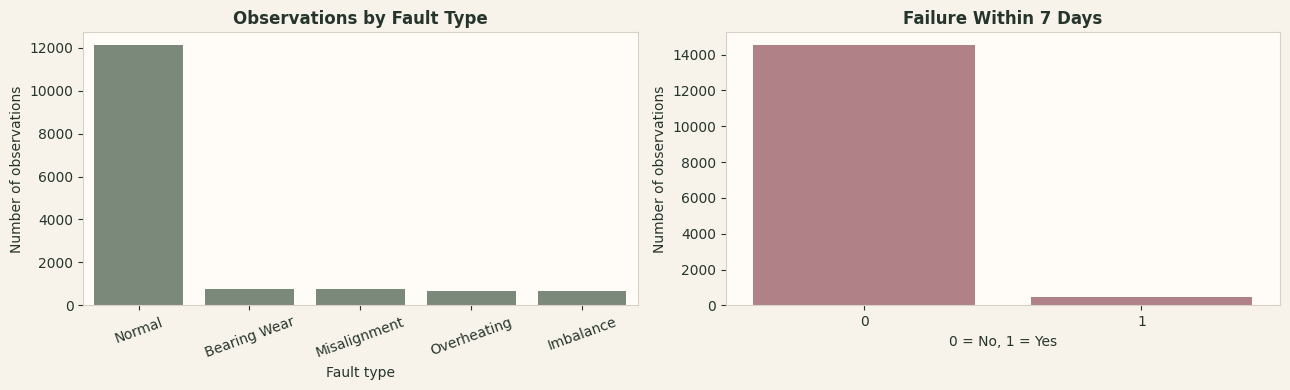

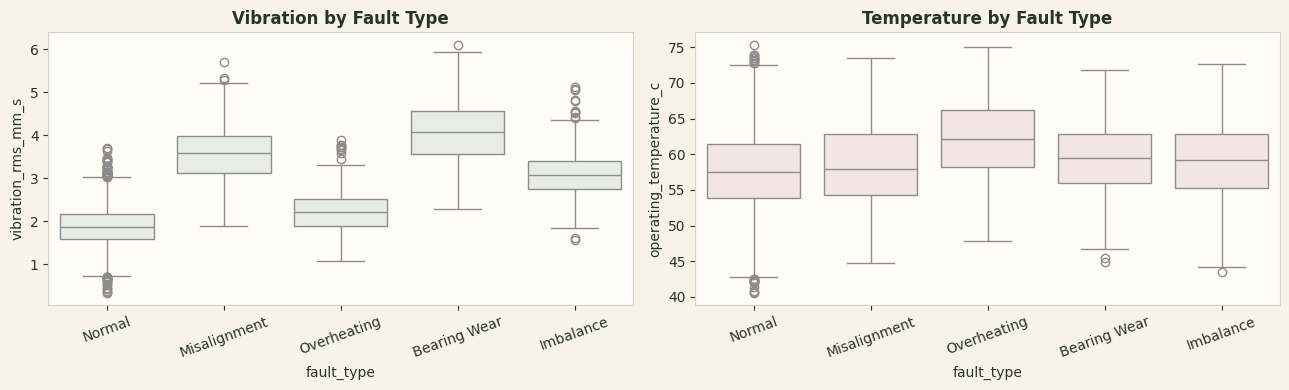

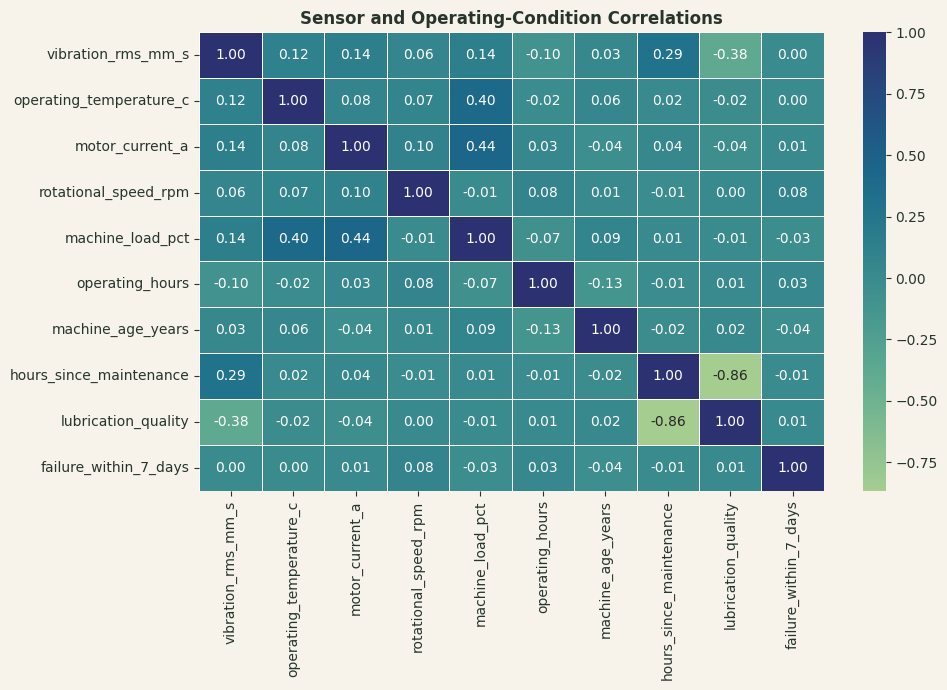

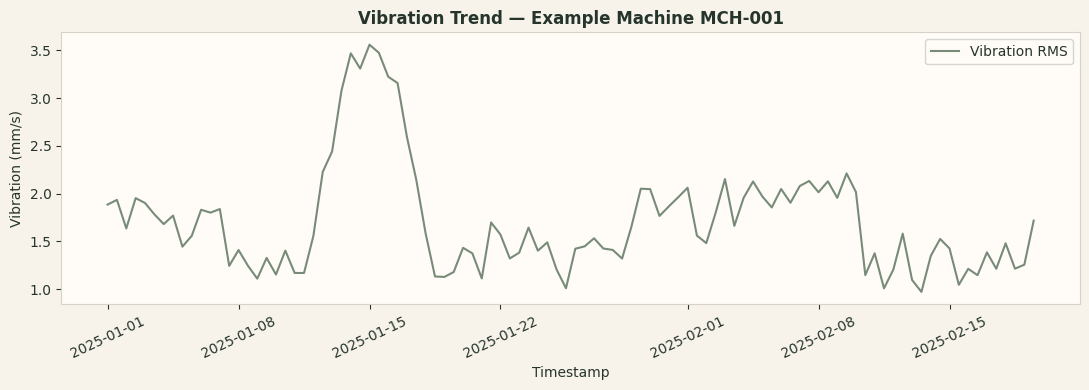

In [6]:
print("Dataset shape:", df.shape)
print("\nNumerical summary:")
display(df[FEATURE_COLUMNS].describe().T)

fault_counts = df[TARGET_FAULT].value_counts()
failure_counts = df[TARGET_FAILURE].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x=TARGET_FAULT, order=fault_counts.index, ax=axes[0], color=SAGE)
axes[0].set_title("Observations by Fault Type")
axes[0].set_xlabel("Fault type")
axes[0].set_ylabel("Number of observations")
axes[0].tick_params(axis="x", rotation=20)

sns.countplot(data=df, x=TARGET_FAILURE, ax=axes[1], color=DUSTY_ROSE)
axes[1].set_title("Failure Within 7 Days")
axes[1].set_xlabel("0 = No, 1 = Yes")
axes[1].set_ylabel("Number of observations")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x=TARGET_FAULT, y="vibration_rms_mm_s", ax=axes[0], color=PALE_SAGE)
axes[0].set_title("Vibration by Fault Type")
axes[0].tick_params(axis="x", rotation=20)
sns.boxplot(data=df, x=TARGET_FAULT, y="operating_temperature_c", ax=axes[1], color=PALE_ROSE)
axes[1].set_title("Temperature by Fault Type")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
correlation = df[FEATURE_COLUMNS + [TARGET_FAILURE]].corr(numeric_only=True)
sns.heatmap(correlation, cmap="crest", annot=True, fmt=".2f", linewidths=0.4)
plt.title("Sensor and Operating-Condition Correlations")
plt.tight_layout()
plt.show()

# Show one machine's sensor trend if timestamps are available.
if "machine_id" in df.columns and "timestamp" in df.columns and df["timestamp"].notna().any():
    example_machine = df["machine_id"].value_counts().index[0]
    one_machine = df[df["machine_id"] == example_machine].sort_values("timestamp")
    plt.figure(figsize=(11, 4))
    plt.plot(one_machine["timestamp"], one_machine["vibration_rms_mm_s"], color=SAGE, label="Vibration RMS")
    plt.title(f"Vibration Trend — Example Machine {example_machine}")
    plt.xlabel("Timestamp")
    plt.ylabel("Vibration (mm/s)")
    plt.xticks(rotation=25)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("A machine trend chart needs machine_id and valid timestamp columns.")

## 7. Select input features and split by machine

We keep the same nine sensor/operating-condition columns as model inputs. If `machine_id` exists, all observations from a machine stay together in one split. This is more careful than randomly splitting individual rows, because the model should be tested on machines it did not see during training.

We create approximately 60% training, 20% validation, and 20% testing groups of machines. The validation set helps us choose a model; the test set is held back for the final evaluation.

In [7]:
X = df[FEATURE_COLUMNS].copy()
y_failure = df[TARGET_FAILURE].copy()
y_fault = df[TARGET_FAULT].copy()


def create_group_splits(data):
    """Create train/validation/test indices, keeping each machine in one split."""
    if "machine_id" in data.columns and data["machine_id"].nunique() >= 10:
        groups = data["machine_id"].astype(str).to_numpy()
        best_split = None
        best_score = float("inf")
        all_failure_classes = set(data[TARGET_FAILURE].astype(str).unique())
        all_fault_classes = set(data[TARGET_FAULT].astype(str).unique())

        for seed in range(42, 142):
            outer = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=seed)
            train_val_idx, test_idx = next(outer.split(data, groups=groups))
            inner = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=seed + 1000)
            train_rel, val_rel = next(inner.split(data.iloc[train_val_idx], groups=groups[train_val_idx]))
            train_idx = train_val_idx[train_rel]
            val_idx = train_val_idx[val_rel]

            train_failure = set(data.iloc[train_idx][TARGET_FAILURE].astype(str).unique())
            train_fault = set(data.iloc[train_idx][TARGET_FAULT].astype(str).unique())
            if train_failure != all_failure_classes or train_fault != all_fault_classes:
                continue

            val_missing = len(all_failure_classes - set(data.iloc[val_idx][TARGET_FAILURE].astype(str)))
            val_missing += len(all_fault_classes - set(data.iloc[val_idx][TARGET_FAULT].astype(str)))
            test_missing = len(all_failure_classes - set(data.iloc[test_idx][TARGET_FAILURE].astype(str)))
            test_missing += len(all_fault_classes - set(data.iloc[test_idx][TARGET_FAULT].astype(str)))
            score = val_missing + 2 * test_missing
            if score < best_score:
                best_score = score
                best_split = (train_idx, val_idx, test_idx)
            if score == 0:
                break

        if best_split is None:
            raise ValueError("Could not create a machine-level split containing all classes in training. Review your machine and label distribution.")
        print("Split method: machine-level split (no machine appears in more than one split).")
        return best_split

    print("Warning: machine_id is missing or has too few machines; using a row-level stratified split instead.")
    all_idx = np.arange(len(data))
    train_val_idx, test_idx = train_test_split(
        all_idx, test_size=0.20, random_state=RANDOM_STATE,
        stratify=data[TARGET_FAULT]
    )
    train_idx, val_idx = train_test_split(
        train_val_idx, test_size=0.25, random_state=RANDOM_STATE,
        stratify=data.iloc[train_val_idx][TARGET_FAULT]
    )
    return train_idx, val_idx, test_idx


train_idx, val_idx, test_idx = create_group_splits(df)

X_train, X_val, X_test = X.iloc[train_idx], X.iloc[val_idx], X.iloc[test_idx]
yf_train, yf_val, yf_test = y_failure.iloc[train_idx], y_failure.iloc[val_idx], y_failure.iloc[test_idx]
yt_train, yt_val, yt_test = y_fault.iloc[train_idx], y_fault.iloc[val_idx], y_fault.iloc[test_idx]

print(f"Training rows:   {len(train_idx):,} ({len(train_idx)/len(df):.1%})")
print(f"Validation rows: {len(val_idx):,} ({len(val_idx)/len(df):.1%})")
print(f"Testing rows:    {len(test_idx):,} ({len(test_idx)/len(df):.1%})")

if "machine_id" in df.columns:
    train_machines = set(df.iloc[train_idx]["machine_id"])
    val_machines = set(df.iloc[val_idx]["machine_id"])
    test_machines = set(df.iloc[test_idx]["machine_id"])
    print("Machine overlap (should all be zero):")
    print("Train/validation:", len(train_machines & val_machines))
    print("Train/test:", len(train_machines & test_machines))
    print("Validation/test:", len(val_machines & test_machines))

Split method: machine-level split (no machine appears in more than one split).
Training rows:   9,000 (60.0%)
Validation rows: 3,000 (20.0%)
Testing rows:    3,000 (20.0%)
Machine overlap (should all be zero):
Train/validation: 0
Train/test: 0
Validation/test: 0


## 8. Train and compare classification algorithms

We compare four algorithms:

- **Logistic Regression:** a simple baseline model.
- **Decision Tree:** learns decision rules that are easier to explain.
- **Random Forest:** combines many decision trees and can learn nonlinear patterns.
- **Gradient Boosting:** builds trees sequentially to improve prediction errors.

The notebook selects the model with the highest **weighted F1-score on validation data**, then retrains that selected model using training plus validation data. The final test set is used only for reporting the final performance.

In [8]:
from sklearn.base import clone


def create_candidate_models():
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE
        ),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=12, min_samples_leaf=4, class_weight="balanced",
            random_state=RANDOM_STATE
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=220, min_samples_leaf=2,
            class_weight="balanced_subsample", n_jobs=-1,
            random_state=RANDOM_STATE
        ),
        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=120, learning_rate=0.06, max_depth=2,
            random_state=RANDOM_STATE
        ),
    }


def make_pipeline(classifier):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", classifier),
    ])


def score_predictions(y_true, y_pred):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_weighted": float(precision_score(y_true, y_pred, average="weighted", zero_division=0)),
        "recall_weighted": float(recall_score(y_true, y_pred, average="weighted", zero_division=0)),
        "f1_weighted": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    }


def train_and_evaluate_task(task_name, y_train, y_val, y_test):
    comparison_rows = []
    fitted_candidates = {}

    for model_name, classifier in create_candidate_models().items():
        model_pipe = make_pipeline(classifier)
        model_pipe.fit(X_train, y_train)
        val_predictions = model_pipe.predict(X_val)
        val_scores = score_predictions(y_val, val_predictions)
        comparison_rows.append({"Model": model_name, **val_scores})
        fitted_candidates[model_name] = model_pipe

    comparison = pd.DataFrame(comparison_rows).sort_values(
        "f1_weighted", ascending=False
    ).reset_index(drop=True)
    best_name = comparison.iloc[0]["Model"]

    # Refit the chosen model on training + validation data. Test data stays unseen.
    X_train_val = pd.concat([X_train, X_val], axis=0)
    y_train_val = pd.concat([y_train, y_val], axis=0)
    final_model = make_pipeline(create_candidate_models()[best_name])
    final_model.fit(X_train_val, y_train_val)

    test_predictions = final_model.predict(X_test)
    classes = list(final_model.named_steps["model"].classes_)
    test_scores = score_predictions(y_test, test_predictions)
    cm = confusion_matrix(y_test, test_predictions, labels=classes)
    report = classification_report(
        y_test, test_predictions, labels=classes,
        output_dict=True, zero_division=0
    )

    result = {
        "task": task_name,
        "best_model": best_name,
        "test_metrics": test_scores,
        "classes": [str(value) for value in classes],
        "confusion_matrix": cm.tolist(),
        "classification_report": report,
        "validation_comparison": comparison.to_dict(orient="records"),
    }
    return final_model, comparison, result

print("Training failure prediction models...")
failure_model, failure_comparison, failure_result = train_and_evaluate_task(
    "Failure within 7 days", yf_train, yf_val, yf_test
)

display(failure_comparison.style.format({
    "accuracy": "{:.3f}", "precision_weighted": "{:.3f}",
    "recall_weighted": "{:.3f}", "f1_weighted": "{:.3f}", "f1_macro": "{:.3f}"
}))
print("Selected failure model:", failure_result["best_model"])

Training failure prediction models...


,Model,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro
0,Gradient Boosting,0.969,0.938,0.969,0.953,0.492
1,Random Forest,0.968,0.938,0.968,0.953,0.492
2,Decision Tree,0.861,0.940,0.861,0.898,0.490
3,Logistic Regression,0.491,0.959,0.491,0.629,0.369


Selected failure model: Gradient Boosting


## 9. Train the fault-type classification model

This second model predicts the current machine condition: Normal, Bearing Wear, Misalignment, Overheating, or Imbalance (depending on which categories are present in your CSV).

In [9]:
print("Training fault-type classification models...")
fault_model, fault_comparison, fault_result = train_and_evaluate_task(
    "Fault type", yt_train, yt_val, yt_test
)

display(fault_comparison.style.format({
    "accuracy": "{:.3f}", "precision_weighted": "{:.3f}",
    "recall_weighted": "{:.3f}", "f1_weighted": "{:.3f}", "f1_macro": "{:.3f}"
}))
print("Selected fault-type model:", fault_result["best_model"])

Training fault-type classification models...


,Model,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro
0,Gradient Boosting,0.846,0.820,0.846,0.830,0.433
1,Random Forest,0.837,0.808,0.837,0.820,0.385
2,Logistic Regression,0.744,0.866,0.744,0.789,0.480
3,Decision Tree,0.731,0.809,0.731,0.765,0.381


Selected fault-type model: Gradient Boosting


## 10. Evaluate the models on the held-out test machines

These are the final metrics from the test set. They estimate how the models perform on machines that were not used for training or model selection.


Failure Within 7 Days
Selected algorithm: Gradient Boosting
accuracy: 0.9593
precision_weighted: 0.9304
recall_weighted: 0.9593
f1_weighted: 0.9410
f1_macro: 0.4977

Classification report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      2881
           1       0.20      0.01      0.02       119

    accuracy                           0.96      3000
   macro avg       0.58      0.50      0.50      3000
weighted avg       0.93      0.96      0.94      3000



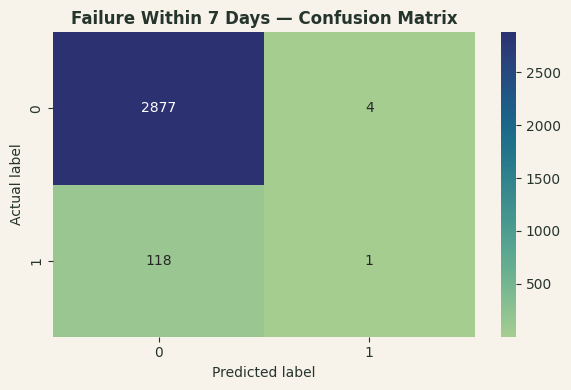


Fault Type Classification
Selected algorithm: Gradient Boosting
accuracy: 0.8690
precision_weighted: 0.8316
recall_weighted: 0.8690
f1_weighted: 0.8472
f1_macro: 0.4741

Classification report:
              precision    recall  f1-score   support

Bearing Wear       0.67      0.70      0.69       160
   Imbalance       0.32      0.29      0.30       121
Misalignment       0.48      0.32      0.39       154
      Normal       0.93      0.99      0.96      2435
 Overheating       0.12      0.02      0.04       130

    accuracy                           0.87      3000
   macro avg       0.50      0.47      0.47      3000
weighted avg       0.83      0.87      0.85      3000



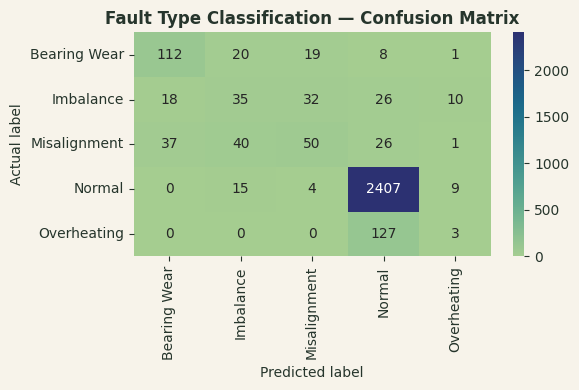

In [10]:
def show_evaluation(result, y_true, y_pred, title):
    metrics = result["test_metrics"]
    print("\n" + title)
    print("Selected algorithm:", result["best_model"])
    for key, value in metrics.items():
        print(f"{key}: {value:.4f}")
    print("\nClassification report:")
    print(classification_report(y_true, y_pred, zero_division=0))

    labels = result["classes"]
    cm = np.array(result["confusion_matrix"])
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="crest",
                xticklabels=labels, yticklabels=labels)
    plt.title(title + " — Confusion Matrix")
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.tight_layout()
    plt.show()

failure_test_predictions = failure_model.predict(X_test)
fault_test_predictions = fault_model.predict(X_test)

show_evaluation(failure_result, yf_test, failure_test_predictions,
                "Failure Within 7 Days")
show_evaluation(fault_result, yt_test, fault_test_predictions,
                "Fault Type Classification")

## 11. Save the trained models and project files

The selected models are saved as `.joblib` files. The Streamlit application will load these files to make predictions. We also save the dataset and model information in the project folder.

In [11]:
# Save trained model pipelines
joblib.dump(failure_model, ARTIFACT_DIR / "failure_model.joblib")
joblib.dump(fault_model, ARTIFACT_DIR / "fault_model.joblib")

# Keep a copy of the dataset beside the app so the app can explore it.
df.to_csv(ARTIFACT_DIR / "dataset_for_app.csv", index=False)

# Prepare a short dataset summary for the app and report.
dataset_summary = {
    "rows": int(len(df)),
    "machines": int(df["machine_id"].nunique()) if "machine_id" in df.columns else None,
    "failure_rate": float(df[TARGET_FAILURE].mean()),
    "fault_counts": {str(k): int(v) for k, v in df[TARGET_FAULT].value_counts().items()},
    "features": FEATURE_COLUMNS,
}

metadata = {
    "project_name": "RepairRadar",
    "features": FEATURE_COLUMNS,
    "failure_target": TARGET_FAILURE,
    "fault_target": TARGET_FAULT,
    "failure_result": failure_result,
    "fault_result": fault_result,
    "dataset_summary": dataset_summary,
    "important_note": "Models were trained on student-generated synthetic data. Outputs are educational demonstrations, not safety-critical industrial advice.",
}

with open(ARTIFACT_DIR / "metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, default=str)

print("Saved project artifacts:")
for item in sorted(ARTIFACT_DIR.iterdir()):
    print("-", item.name, f"({item.stat().st_size:,} bytes)")

Saved project artifacts:
- dataset_for_app.csv (1,604,095 bytes)
- failure_model.joblib (101,553 bytes)
- fault_model.joblib (444,114 bytes)
- metadata.json (6,592 bytes)


## 12. Build the redesigned Streamlit application

The application uses a **single horizontal header** for navigation. There is no left sidebar. The main pages are:

- **Overview:** dataset and machine-condition dashboard.
- **Predict:** enter sensor readings and obtain both model predictions.
- **Dataset:** inspect observations and compare sensor readings by fault type.
- **Model results:** review validation comparisons, test metrics, and confusion matrices.
- **About:** project scope, workflow, and limitations.

The interface uses muted sage green, dusty rose, and warm cream. Plotly charts are forced to use a light template so chart titles, axes, tick labels, and legends remain dark and readable even when Colab or the browser prefers dark mode. The Streamlit sidebar is disabled; navigation appears in the top header.

In [12]:
%%writefile /content/RepairRadar/app.py
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st

# -----------------------------------------------------------------------------
# RepairRadar — clean, responsive, top-navigation Streamlit interface
# -----------------------------------------------------------------------------
BASE_DIR = Path(__file__).resolve().parent
ARTIFACT_DIR = BASE_DIR / "artifacts"
DATA_PATH = ARTIFACT_DIR / "dataset_for_app.csv"
HERO_PATH = BASE_DIR / "repairradar_machine_banner.jpg"
BEARING_PATH = BASE_DIR / "repairradar_bearing_detail.jpg"

SAGE = "#788B78"
DUSTY_ROSE = "#B87980"
WARM_CREAM = "#F7F3EA"
DARK_GREEN = "#26352C"
MUTED = "#657568"
PALE_SAGE = "#E7EDE4"
PALE_ROSE = "#F3E3E3"
CARD = "#FFFCF7"
PALETTE = [SAGE, DUSTY_ROSE, "#C99F68", "#91A79D", "#92777B"]

st.set_page_config(
    page_title="RepairRadar | Predictive Maintenance",
    page_icon="⚙️",
    layout="wide",
    initial_sidebar_state="collapsed",
)

# Hide Streamlit's default sidebar and dark top toolbar. Navigation is in our header.
st.markdown(
    """
<style>
@import url('https://fonts.googleapis.com/css2?family=DM+Sans:wght@400;500;600;700;800&display=swap');
:root {
  --rr-cream: #F7F3EA;
  --rr-card: #FFFCF7;
  --rr-sage: #788B78;
  --rr-rose: #B87980;
  --rr-dark: #26352C;
  --rr-muted: #657568;
  --rr-border: #E5DDD1;
}
html, body, [class*="css"], [data-testid="stAppViewContainer"] {
  font-family: 'DM Sans', sans-serif !important;
  color: var(--rr-dark) !important;
}
.stApp, [data-testid="stAppViewContainer"], [data-testid="stMain"],
[data-testid="stMainBlockContainer"] {
  background: var(--rr-cream) !important;
  color: var(--rr-dark) !important;
}
/* Remove the built-in navigation sidebar completely. */
section[data-testid="stSidebar"], [data-testid="collapsedControl"] {
  display: none !important;
  width: 0 !important;
}
/* Remove the black Streamlit toolbar strip shown in some Colab previews. */
header[data-testid="stHeader"], [data-testid="stToolbar"],
[data-testid="stDecoration"], #MainMenu, footer {
  display: none !important;
  visibility: hidden !important;
  height: 0 !important;
}
.block-container, [data-testid="stMainBlockContainer"] {
  max-width: 1480px !important;
  padding-top: 1.05rem !important;
  padding-bottom: 3rem !important;
  padding-left: clamp(1rem, 3vw, 2.7rem) !important;
  padding-right: clamp(1rem, 3vw, 2.7rem) !important;
}
.stMarkdown, .stMarkdown p, .stMarkdown li, .stCaption,
[data-testid="stCaptionContainer"], label, .stText, .stAlert,
[data-testid="stMetricLabel"], [data-testid="stMetricValue"] {
  color: var(--rr-dark) !important;
}
h1, h2, h3, h4, h5, h6, p, li {
  color: var(--rr-dark) !important;
}
h1, h2, h3 { letter-spacing: -0.035em; }
small, .rr-muted { color: var(--rr-muted) !important; }

/* Top brand and navigation header */
.rr-header {
  display: flex; align-items: center; justify-content: space-between;
  gap: 1.2rem; padding: .35rem 0 1rem 0;
}
.rr-brand { display: flex; align-items: center; gap: .8rem; min-width: 230px; }
.rr-mark {
  width: 46px; height: 46px; border-radius: 15px;
  display:flex; align-items:center; justify-content:center;
  color: white; font-size: 1.35rem; font-weight: 800;
  background: linear-gradient(145deg, var(--rr-sage), #5F735F);
  box-shadow: 0 7px 16px rgba(65,85,67,.16);
}
.rr-brand-name { font-size: 1.28rem; font-weight: 800; line-height: 1.1; color: var(--rr-dark); }
.rr-brand-tag { font-size: .78rem; color: var(--rr-muted); margin-top: .2rem; }
.rr-header-note {
  padding: .48rem .78rem; border: 1px solid var(--rr-border);
  border-radius: 999px; background: var(--rr-card); color: var(--rr-muted);
  font-size: .78rem; white-space: nowrap;
}
.rr-rule { height: 1px; background: #DED7CB; margin: .15rem 0 1.35rem 0; }
/* Horizontal Streamlit radio is the replacement for the sidebar menu. */
div[data-testid="stRadio"] { margin: 0 !important; }
div[data-testid="stRadio"] > label { display: none !important; }
div[data-testid="stRadio"] [role="radiogroup"] {
  display: flex !important; flex-direction: row !important; flex-wrap: wrap !important;
  justify-content: flex-end !important; gap: .38rem !important;
}
div[data-testid="stRadio"] [role="radiogroup"] label {
  background: var(--rr-card) !important; border: 1px solid var(--rr-border) !important;
  border-radius: 999px !important; padding: .43rem .78rem !important;
  margin: 0 !important; min-height: 38px !important;
}
div[data-testid="stRadio"] [role="radiogroup"] label:has(input:checked) {
  background: var(--rr-dark) !important; border-color: var(--rr-dark) !important;
}
div[data-testid="stRadio"] [role="radiogroup"] label:has(input:checked) * {
  color: #FFFFFF !important;
}
div[data-testid="stRadio"] [role="radiogroup"] label p {
  font-size: .82rem !important; font-weight: 700 !important; margin: 0 !important;
}
div[data-testid="stRadio"] input { accent-color: var(--rr-rose) !important; }

/* Intro and cards */
.rr-eyebrow { color: var(--rr-sage) !important; font-size: .72rem; font-weight: 800;
  letter-spacing: .14em; text-transform: uppercase; }
.rr-title { color: var(--rr-dark) !important; font-size: clamp(2rem, 3.3vw, 3.15rem);
  line-height: 1.04; font-weight: 800; letter-spacing: -.055em; margin: .25rem 0 .45rem 0; }
.rr-title span { color: var(--rr-rose) !important; }
.rr-subtitle { color: var(--rr-muted) !important; font-size: 1.02rem; line-height: 1.55; }
.rr-hero-note {
  background: linear-gradient(110deg, #E7EDE4 0%, #F7F3EA 56%, #F3E3E3 100%);
  border: 1px solid var(--rr-border); border-radius: 18px;
  padding: 1rem 1.25rem; margin: .8rem 0 1.35rem 0; color: var(--rr-dark) !important;
}
.rr-hero-note b { color: var(--rr-dark) !important; }
.rr-section-title { color: var(--rr-dark) !important; font-size: 1.35rem;
  font-weight: 800; letter-spacing: -.035em; margin: .35rem 0 .9rem 0; }
.rr-section-sub { color: var(--rr-muted) !important; margin-top: -.45rem; margin-bottom: 1rem; }
.rr-card {
  background: var(--rr-card); border: 1px solid var(--rr-border);
  border-radius: 18px; padding: 1rem 1.1rem;
  box-shadow: 0 5px 18px rgba(45,57,46,.035); height: 100%;
}
.rr-card-label { color: var(--rr-muted) !important; font-size: .82rem; font-weight: 600; }
.rr-card-value { color: var(--rr-dark) !important; font-size: 1.9rem; font-weight: 800;
  letter-spacing: -.045em; margin-top: .32rem; }
.rr-card-foot { color: var(--rr-muted) !important; font-size: .75rem; margin-top: .15rem; }
.rr-note {
  background: var(--rr-pale-sage, #E7EDE4); border-left: 4px solid var(--rr-sage);
  border-radius: 10px; padding: .85rem 1rem; color: var(--rr-dark) !important;
}
.rr-risk-high { background: #F3E3E3; border: 1px solid #E6C8CB; }
.rr-risk-medium { background: #F5EBDD; border: 1px solid #E8D6B9; }
.rr-risk-low { background: #E7EDE4; border: 1px solid #D4DED0; }
.rr-risk-value { color: var(--rr-dark) !important; font-size: 2.35rem; font-weight: 800; }

/* Streamlit native widgets */
[data-testid="stMetric"] {
  background: var(--rr-card) !important; border: 1px solid var(--rr-border) !important;
  border-radius: 17px !important; padding: 14px 16px !important;
  box-shadow: 0 4px 14px rgba(45,57,46,.035);
}
[data-testid="stMetricLabel"], [data-testid="stMetricLabel"] p {
  color: var(--rr-muted) !important; font-size: .82rem !important;
}
[data-testid="stMetricValue"], [data-testid="stMetricValue"] div {
  color: var(--rr-dark) !important; font-weight: 800 !important;
}
[data-testid="stTextInput"] input, [data-testid="stNumberInput"] input,
[data-testid="stSelectbox"] div[data-baseweb="select"] > div,
[data-testid="stMultiSelect"] div[data-baseweb="select"] > div {
  background: var(--rr-card) !important; color: var(--rr-dark) !important;
  border-color: #D9D1C5 !important; border-radius: 10px !important;
}
[data-testid="stNumberInput"] button { color: var(--rr-dark) !important; }
.stButton > button, [data-testid="stFormSubmitButton"] button, .stDownloadButton button {
  background: var(--rr-rose) !important; color: #FFFFFF !important;
  border: 0 !important; border-radius: 11px !important;
  font-weight: 700 !important; min-height: 2.65rem !important;
}
.stButton > button:hover, [data-testid="stFormSubmitButton"] button:hover,
.stDownloadButton button:hover { background: #9F646C !important; color: #FFFFFF !important; }
[data-testid="stDataFrame"] { border: 1px solid var(--rr-border); border-radius: 12px; }
[data-testid="stAlert"] { border-radius: 13px !important; }
hr { border-color: var(--rr-border) !important; }

/* Responsive layout */
@media (max-width: 900px) {
  .rr-header { align-items: flex-start; flex-direction: column; }
  div[data-testid="stRadio"] [role="radiogroup"] { justify-content: flex-start !important; }
  .rr-header-note { display: none; }
}
@media (max-width: 600px) {
  .rr-title { font-size: 2rem; }
  div[data-testid="stRadio"] [role="radiogroup"] label { padding: .35rem .58rem !important; }
}

/* Final layout hardening: no sidebar, no dark toolbar, no leftover top gap. */
[data-testid="stSidebar"],
[data-testid="stSidebarNav"],
[data-testid="stSidebarContent"],
[data-testid="stSidebarCollapsedControl"],
[data-testid="collapsedControl"] {
  display: none !important;
  visibility: hidden !important;
  width: 0 !important;
  min-width: 0 !important;
}
[data-testid="stAppViewContainer"] > section,
[data-testid="stMain"],
[data-testid="stMainBlockContainer"] {
  margin-left: 0 !important;
  width: 100% !important;
  max-width: 100% !important;
}
header[data-testid="stHeader"],
[data-testid="stToolbar"],
[data-testid="stDecoration"],
[data-testid="stStatusWidget"],
[data-testid="stAppDeployButton"],
#MainMenu, footer {
  display: none !important;
  visibility: hidden !important;
  height: 0 !important;
  min-height: 0 !important;
  background: var(--rr-cream) !important;
}
body, html, #root, .stApp,
[data-testid="stAppViewContainer"],
[data-testid="stMain"] {
  background: var(--rr-cream) !important;
  color: var(--rr-dark) !important;
}
[data-testid="stMainBlockContainer"] {
  padding-top: .8rem !important;
}
/* Header navigation looks like tabs rather than a vertical radio list. */
div[data-testid="stRadio"] [role="radiogroup"] label {
  display: inline-flex !important;
  align-items: center !important;
  justify-content: center !important;
  min-height: 40px !important;
  padding: .48rem .88rem !important;
  border-radius: 999px !important;
  background: #FFFCF7 !important;
  border: 1px solid #E5DDD1 !important;
  color: #26352C !important;
}
div[data-testid="stRadio"] [role="radiogroup"] input[type="radio"] {
  display: none !important;
}
div[data-testid="stRadio"] [role="radiogroup"] label p,
div[data-testid="stRadio"] [role="radiogroup"] label span {
  color: #26352C !important;
  font-weight: 700 !important;
}
div[data-testid="stRadio"] [role="radiogroup"] label:has(input:checked) {
  background: #26352C !important;
  border-color: #26352C !important;
}
div[data-testid="stRadio"] [role="radiogroup"] label:has(input:checked) p,
div[data-testid="stRadio"] [role="radiogroup"] label:has(input:checked) span {
  color: #FFFFFF !important;
}
.rr-header-shell {
  display: flex; align-items: center; justify-content: space-between;
  gap: 1rem; width: 100%; padding: .25rem 0 .8rem 0;
}
.rr-status {
  display: inline-flex; align-items: center; gap: .42rem;
  padding: .48rem .78rem; border-radius: 999px;
  background: #E7EDE4; color: #405844 !important;
  border: 1px solid #D4DED0; font-size: .77rem; font-weight: 700;
  white-space: nowrap;
}
.rr-status-dot {
  display: inline-block; width: .5rem; height: .5rem;
  background: #64866B; border-radius: 50%;
}
.rr-intro-panel {
  display: flex; align-items: center; justify-content: space-between;
  gap: 1.5rem; padding: .9rem 0 .5rem 0;
}
.rr-intro-copy { flex: 1 1 55%; min-width: 0; }
.rr-image-frame {
  overflow: hidden; border-radius: 18px; border: 1px solid #E5DDD1;
  box-shadow: 0 8px 24px rgba(45,57,46,.07);
}
.rr-image-frame img { display: block; width: 100%; height: auto; object-fit: cover; }
[data-testid="stPlotlyChart"] { background: transparent !important; }
[data-testid="stPlotlyChart"] iframe { background: transparent !important; }
@media (max-width: 900px) {
  .rr-header-shell, .rr-intro-panel { display: block; }
  .rr-status { margin-top: .75rem; }
  .rr-intro-copy { margin-bottom: .7rem; }
}

</style>
""",
    unsafe_allow_html=True,
)


@st.cache_resource
def load_assets():
    failure = joblib.load(ARTIFACT_DIR / "failure_model.joblib")
    fault = joblib.load(ARTIFACT_DIR / "fault_model.joblib")
    with open(ARTIFACT_DIR / "metadata.json", "r", encoding="utf-8") as file:
        meta = json.load(file)
    return failure, fault, meta


@st.cache_data
def load_data():
    return pd.read_csv(DATA_PATH)


def model_classes(model):
    estimator = model.named_steps["model"] if hasattr(model, "named_steps") else model
    return list(estimator.classes_)


def style_figure(fig, height=350):
    """Apply readable text, axis, grid, and background colors to every chart."""
    fig.update_layout(
        template="plotly_white",
        height=height,
        font=dict(family="DM Sans, sans-serif", size=12, color=DARK_GREEN),
        title_font=dict(family="DM Sans, sans-serif", size=17, color=DARK_GREEN),
        legend=dict(font=dict(color=DARK_GREEN), bgcolor="rgba(0,0,0,0)"),
        paper_bgcolor="rgba(0,0,0,0)",
        plot_bgcolor=CARD,
        margin=dict(l=18, r=18, t=58, b=18),
        hoverlabel=dict(bgcolor=CARD, font=dict(color=DARK_GREEN)),
    )
    fig.update_xaxes(
        color=DARK_GREEN,
        title_font=dict(color=DARK_GREEN),
        tickfont=dict(color=MUTED),
        gridcolor="#ECE5DA",
        linecolor="#D9D1C5",
        zerolinecolor="#E6DED2",
    )
    fig.update_yaxes(
        color=DARK_GREEN,
        title_font=dict(color=DARK_GREEN),
        tickfont=dict(color=MUTED),
        gridcolor="#ECE5DA",
        linecolor="#D9D1C5",
        zerolinecolor="#E6DED2",
    )
    return fig


def card(label, value, foot=""):
    st.markdown(
        f"<div class='rr-card'><div class='rr-card-label'>{label}</div>"
        f"<div class='rr-card-value'>{value}</div>"
        f"<div class='rr-card-foot'>{foot}</div></div>",
        unsafe_allow_html=True,
    )


try:
    failure_model, fault_model, metadata = load_assets()
    df = load_data()
except Exception as error:
    st.error("RepairRadar could not load its saved project files.")
    st.info("Run the notebook's model-training and save section before launching the app.")
    st.exception(error)
    st.stop()

features = metadata["features"]

# -----------------------------------------------------------------------------
# Main top navigation — sidebar is intentionally not used.
# -----------------------------------------------------------------------------
brand_col, nav_col, status_col = st.columns([1.0, 3.1, 0.85], vertical_alignment="center")
with brand_col:
    st.markdown(
        """
        <div class="rr-brand">
          <div class="rr-mark">⚙</div>
          <div>
            <div class="rr-brand-name">RepairRadar</div>
            <div class="rr-brand-tag">Predict · Prevent · Perform</div>
          </div>
        </div>
        """,
        unsafe_allow_html=True,
    )
with nav_col:
    page = st.radio(
        "Main navigation",
        ["Overview", "Predict", "Dataset", "Model results", "About"],
        horizontal=True,
        label_visibility="collapsed",
        key="repairradar_top_navigation_v2",
    )
with status_col:
    st.markdown(
        '<div class="rr-status"><span class="rr-status-dot"></span>System ready</div>',
        unsafe_allow_html=True,
    )

st.markdown("<div class='rr-rule'></div>", unsafe_allow_html=True)

page_intro = {
    "Overview": ("Intelligent machine care", "Welcome to <span>RepairRadar</span>", "Understand machine conditions. Predict possible faults. Plan maintenance earlier."),
    "Predict": ("Predictive assessment", "Check machine <span>health</span>", "Enter current sensor readings to estimate short-term failure risk and identify possible fault types."),
    "Dataset": ("Synthetic data explorer", "Explore the <span>dataset</span>", "Inspect machine observations, compare fault categories, and understand the simulated sensor patterns."),
    "Model results": ("Model evaluation", "Measure model <span>performance</span>", "Review validation comparisons and results from machines held out during training."),
    "About": ("Project information", "About <span>RepairRadar</span>", "A student-built predictive-maintenance prototype using an original synthetic industrial dataset."),
}
eyebrow, page_title, page_subtitle = page_intro[page]
intro_col, image_col = st.columns([1.35, 1], gap="large", vertical_alignment="center")
with intro_col:
    st.markdown(f"<div class='rr-eyebrow'>{eyebrow}</div>", unsafe_allow_html=True)
    st.markdown(f"<div class='rr-title'>{page_title}</div>", unsafe_allow_html=True)
    st.markdown(f"<div class='rr-subtitle'>{page_subtitle}</div>", unsafe_allow_html=True)
with image_col:
    if HERO_PATH.exists():
        st.image(str(HERO_PATH), use_container_width=True)

st.markdown(
    """
    <div class="rr-hero-note">
      <b>Keep your machines healthy.</b><br>
      RepairRadar analyzes operating conditions and sensor readings to demonstrate
      early machine-failure prediction and support proactive maintenance planning.
    </div>
    """,
    unsafe_allow_html=True,
)

# -----------------------------------------------------------------------------
# OVERVIEW
# -----------------------------------------------------------------------------
if page == "Overview":
    st.markdown("<div class='rr-section-title'>System overview</div>", unsafe_allow_html=True)
    machine_count = int(df["machine_id"].nunique()) if "machine_id" in df.columns else 0
    row_count = len(df)
    failure_rate = float(pd.to_numeric(df["failure_within_7_days"], errors="coerce").mean())
    fault_count = int(df["fault_type"].nunique())

    metric_cols = st.columns(4)
    with metric_cols[0]:
        card("Machines represented", f"{machine_count:,}", "Unique simulated machines")
    with metric_cols[1]:
        card("Sensor observations", f"{row_count:,}", "Synthetic operating records")
    with metric_cols[2]:
        card("7-day failure labels", f"{failure_rate:.1%}", "Share of positive labels")
    with metric_cols[3]:
        card("Fault categories", str(fault_count), "Machine condition classes")

    st.markdown("<br>", unsafe_allow_html=True)
    left, right = st.columns(2, gap="large")
    with left:
        fault_counts = (
            df["fault_type"].value_counts().rename_axis("Fault type")
            .reset_index(name="Observations")
        )
        fig = px.bar(
            fault_counts, x="Fault type", y="Observations", color="Fault type",
            color_discrete_sequence=PALETTE, title="Machine condition distribution",
        )
        fig.update_layout(showlegend=False)
        st.plotly_chart(style_figure(fig, 370), use_container_width=True, theme=None)
    with right:
        fail_counts = (
            df["failure_within_7_days"].value_counts().sort_index()
            .rename(index={0: "No simulated failure", 1: "Failure within 7 days"})
            .rename_axis("Outcome").reset_index(name="Observations")
        )
        fig = px.pie(
            fail_counts, names="Outcome", values="Observations", hole=.62,
            color_discrete_sequence=[SAGE, DUSTY_ROSE], title="Seven-day failure labels",
        )
        fig.update_traces(textposition="inside", textinfo="percent+label", textfont=dict(color=DARK_GREEN))
        st.plotly_chart(style_figure(fig, 370), use_container_width=True, theme=None)

    left, right = st.columns(2, gap="large")
    with left:
        fig = px.box(
            df, x="fault_type", y="vibration_rms_mm_s", color="fault_type",
            color_discrete_sequence=PALETTE, title="Vibration by machine condition",
        )
        fig.update_layout(showlegend=False)
        st.plotly_chart(style_figure(fig, 360), use_container_width=True, theme=None)
    with right:
        fig = px.scatter(
            df.sample(min(2500, len(df)), random_state=42),
            x="operating_temperature_c", y="motor_current_a", color="fault_type",
            color_discrete_sequence=PALETTE, opacity=.72,
            title="Operating temperature vs motor current",
        )
        st.plotly_chart(style_figure(fig, 360), use_container_width=True, theme=None)

    st.markdown(
        "<div class='rr-note'>All figures describe the student-generated synthetic dataset. "
        "They are not live readings from real industrial machines.</div>",
        unsafe_allow_html=True,
    )

# -----------------------------------------------------------------------------
# PREDICT
# -----------------------------------------------------------------------------
elif page == "Predict":
    st.markdown("<div class='rr-section-title'>Machine health assessment</div>", unsafe_allow_html=True)
    st.markdown(
        "<div class='rr-section-sub'>Enter a machine's current sensor readings. "
        "The trained models will estimate short-term failure risk and classify its condition.</div>",
        unsafe_allow_html=True,
    )

    defaults = {
        "vibration_rms_mm_s": 4.5,
        "operating_temperature_c": 75.0,
        "motor_current_a": 12.0,
        "rotational_speed_rpm": 1500.0,
        "machine_load_pct": 80.0,
        "operating_hours": 4500.0,
        "machine_age_years": 4.0,
        "hours_since_maintenance": 60.0,
        "lubrication_quality": 3.0,
    }
    labels = {
        "vibration_rms_mm_s": "Vibration RMS (mm/s)",
        "operating_temperature_c": "Operating temperature (°C)",
        "motor_current_a": "Motor current (A)",
        "rotational_speed_rpm": "Rotational speed (RPM)",
        "machine_load_pct": "Machine load (%)",
        "operating_hours": "Total operating hours",
        "machine_age_years": "Machine age (years)",
        "hours_since_maintenance": "Hours since maintenance",
        "lubrication_quality": "Lubrication quality (1–5)",
    }

    form_col, info_col = st.columns([1.45, 1], gap="large")
    with form_col:
        st.markdown("<div class='rr-card-label'>MACHINE SENSOR INPUTS</div>", unsafe_allow_html=True)
        with st.form("machine_input_form"):
            input_columns = st.columns(3)
            input_values = {}
            for index, feature in enumerate(features):
                with input_columns[index % 3]:
                    median_value = float(pd.to_numeric(df[feature], errors="coerce").median())
                    initial_value = defaults.get(feature, median_value)
                    input_values[feature] = st.number_input(
                        labels.get(feature, feature.replace("_", " ").title()),
                        value=float(initial_value), format="%.2f", key=f"input_{feature}",
                    )
            submitted = st.form_submit_button("Analyze machine health", use_container_width=True)
    with info_col:
        if BEARING_PATH.exists():
            st.image(str(BEARING_PATH), use_container_width=True)
        st.markdown(
            "<div class='rr-note'><b>How to use</b><br>Enter the latest available machine readings, "
            "then select <b>Analyze machine health</b>. The displayed predictions come from your "
            "trained models.</div>",
            unsafe_allow_html=True,
        )

    if submitted:
        input_frame = pd.DataFrame([[input_values[column] for column in features]], columns=features)
        failure_prediction = failure_model.predict(input_frame)[0]
        fault_prediction = fault_model.predict(input_frame)[0]

        failure_probability = None
        if hasattr(failure_model, "predict_proba"):
            probabilities = failure_model.predict_proba(input_frame)[0]
            failure_classes = model_classes(failure_model)
            positive_index = next(
                (i for i, value in enumerate(failure_classes)
                 if value == 1 or str(value).strip().lower() in {"1", "true", "yes"}),
                None,
            )
            if positive_index is not None:
                failure_probability = float(probabilities[positive_index])
        if failure_probability is None:
            failure_probability = float(
                str(failure_prediction).strip().lower() in {"1", "true", "yes"}
            )

        fault_probabilities = None
        fault_classes = model_classes(fault_model)
        fault_confidence = None
        if hasattr(fault_model, "predict_proba"):
            fault_probabilities = fault_model.predict_proba(input_frame)[0]
            predicted_index = fault_classes.index(fault_prediction)
            fault_confidence = float(fault_probabilities[predicted_index])

        if failure_probability >= 0.70:
            priority, risk_class = "High", "rr-risk-high"
        elif failure_probability >= 0.35:
            priority, risk_class = "Medium", "rr-risk-medium"
        else:
            priority, risk_class = "Low", "rr-risk-low"

        st.markdown("<div class='rr-section-title'>Prediction results</div>", unsafe_allow_html=True)
        result_left, result_right = st.columns([1.05, 1], gap="large")
        with result_left:
            st.markdown(
                f"<div class='rr-card {risk_class}'>"
                f"<div class='rr-card-label'>PREDICTED MAINTENANCE PRIORITY</div>"
                f"<div class='rr-card-value'>{priority} priority</div>"
                f"<div class='rr-card-foot'>Estimated failure probability within the next seven days</div>"
                f"<div class='rr-risk-value'>{failure_probability:.1%}</div></div>",
                unsafe_allow_html=True,
            )
            st.progress(min(max(failure_probability, 0.0), 1.0))
            st.metric(
                "Predicted fault type", str(fault_prediction),
                None if fault_confidence is None else f"{fault_confidence:.1%} model confidence",
            )
        with result_right:
            if fault_probabilities is not None:
                fault_chart = pd.DataFrame({
                    "Fault type": [str(value) for value in fault_classes],
                    "Model probability": fault_probabilities,
                })
                fig = px.bar(
                    fault_chart, x="Fault type", y="Model probability", color="Fault type",
                    color_discrete_sequence=PALETTE, title="Fault-type model scores",
                )
                fig.update_yaxes(tickformat=".0%", range=[0, 1])
                fig.update_layout(showlegend=False)
                st.plotly_chart(style_figure(fig, 330), use_container_width=True, theme=None)

        st.markdown(
            "<div class='rr-note'>Priority levels are illustrative display bands for this educational prototype. "
            "They are not certified industrial safety thresholds.</div>",
            unsafe_allow_html=True,
        )

# -----------------------------------------------------------------------------
# DATASET
# -----------------------------------------------------------------------------
elif page == "Dataset":
    st.markdown("<div class='rr-section-title'>Explore the synthetic dataset</div>", unsafe_allow_html=True)
    st.markdown(
        "<div class='rr-section-sub'>Filter machine observations, inspect sensor values, "
        "and compare operating conditions across fault categories.</div>",
        unsafe_allow_html=True,
    )
    fault_options = sorted(df["fault_type"].dropna().unique().tolist())
    selected_faults = st.multiselect("Filter by fault type", fault_options, default=fault_options)
    filtered = df[df["fault_type"].isin(selected_faults)]
    st.caption(f"Showing {len(filtered):,} of {len(df):,} observations")
    st.dataframe(filtered.head(500), use_container_width=True, height=340)

    if not filtered.empty:
        left, right = st.columns(2, gap="large")
        with left:
            fig = px.histogram(
                filtered, x="vibration_rms_mm_s", color="fault_type", barmode="overlay",
                opacity=.72, color_discrete_sequence=PALETTE, title="Vibration distribution",
            )
            st.plotly_chart(style_figure(fig, 350), use_container_width=True, theme=None)
        with right:
            fig = px.scatter(
                filtered.sample(min(2500, len(filtered)), random_state=42),
                x="operating_temperature_c", y="motor_current_a", color="fault_type",
                color_discrete_sequence=PALETTE, title="Temperature vs motor current",
            )
            st.plotly_chart(style_figure(fig, 350), use_container_width=True, theme=None)
    else:
        st.info("No observations match the selected fault filters.")

# -----------------------------------------------------------------------------
# MODEL RESULTS
# -----------------------------------------------------------------------------
elif page == "Model results":
    st.markdown("<div class='rr-section-title'>Model performance</div>", unsafe_allow_html=True)
    st.markdown(
        "<div class='rr-section-sub'>Compare the selected classifiers using the held-out test machines.</div>",
        unsafe_allow_html=True,
    )
    task_choice = st.selectbox("Prediction task", ["Failure within 7 days", "Fault type"])
    result = metadata["failure_result"] if task_choice == "Failure within 7 days" else metadata["fault_result"]
    metrics = result["test_metrics"]
    st.markdown(f"**Selected algorithm:** {result['best_model']} &nbsp; · &nbsp; **Test set:** unseen machines")

    metric_cols = st.columns(4)
    metric_labels = [
        ("Accuracy", "accuracy"),
        ("Precision", "precision_weighted"),
        ("Recall", "recall_weighted"),
        ("F1 score", "f1_weighted"),
    ]
    for col, (label, key) in zip(metric_cols, metric_labels):
        with col:
            card(label, f"{metrics[key]:.1%}", "Held-out test performance")

    st.markdown("<br>", unsafe_allow_html=True)
    comparison = pd.DataFrame(result["validation_comparison"])
    st.markdown("#### Validation model comparison")
    st.dataframe(
        comparison.style.format({
            "accuracy": "{:.3f}", "precision_weighted": "{:.3f}",
            "recall_weighted": "{:.3f}", "f1_weighted": "{:.3f}", "f1_macro": "{:.3f}",
        }),
        use_container_width=True, hide_index=True,
    )

    cm = np.array(result["confusion_matrix"])
    class_labels = result["classes"]
    fig = go.Figure(data=go.Heatmap(
        z=cm, x=class_labels, y=class_labels,
        colorscale=[[0, WARM_CREAM], [.5, "#B9C8B7"], [1, SAGE]],
        text=cm, texttemplate="%{text}",
        textfont=dict(color=DARK_GREEN),
        colorbar=dict(tickfont=dict(color=DARK_GREEN)),
    ))
    fig.update_layout(title="Test-set confusion matrix", xaxis_title="Predicted", yaxis_title="Actual")
    st.plotly_chart(style_figure(fig, 430), use_container_width=True, theme=None)
    st.caption("Validation results select the model. The displayed metrics and confusion matrix use the held-out test set.")

# -----------------------------------------------------------------------------
# ABOUT
# -----------------------------------------------------------------------------
else:
    st.markdown("<div class='rr-section-title'>About RepairRadar</div>", unsafe_allow_html=True)
    st.markdown(
        "RepairRadar is a student predictive-maintenance prototype. It analyzes machine operating "
        "conditions and sensor readings to estimate simulated failure risk within seven days and "
        "classify the current machine condition."
    )
    left, right = st.columns([1.15, 1], gap="large")
    with left:
        st.markdown("#### Project workflow")
        st.markdown(
            "1. Generate an original synthetic industrial-machine dataset.\n"
            "2. Explore and prepare sensor data.\n"
            "3. Compare classification algorithms.\n"
            "4. Evaluate using held-out machines.\n"
            "5. Use trained models in this Streamlit application."
        )
        st.markdown("#### Fault categories")
        st.write("Normal · Bearing Wear · Misalignment · Overheating · Imbalance")
    with right:
        if BEARING_PATH.exists():
            st.image(str(BEARING_PATH), use_container_width=True)
    st.warning(
        "The models were trained on student-generated synthetic data. This prototype has not been "
        "validated for real factories or safety-critical maintenance decisions. Real deployment "
        "would require real sensor data, engineering validation, monitoring, and domain-expert review."
    )

st.markdown("<div class='rr-rule'></div>", unsafe_allow_html=True)
st.markdown(
    "<div style='text-align:center;color:#657568;font-size:.78rem;'>"
    "RepairRadar · Educational predictive-maintenance prototype · Synthetic data only</div>",
    unsafe_allow_html=True,
)


Writing /content/RepairRadar/app.py


## 13. Launch the redesigned Streamlit application in Google Colab

This cell **stops an earlier RepairRadar Streamlit process before starting the updated app**. That prevents Colab from continuing to show an older version with a sidebar. It also writes a light Streamlit theme and uses minimal toolbar mode so the app begins with the sage/cream interface instead of a dark toolbar. The app opens in Colab's built-in port preview on port `8501`.

In [13]:
import subprocess
import time
import socket
import os
from pathlib import Path
from IPython.display import display, Markdown

# Explicitly use a light Streamlit theme and minimal toolbar.
THEME_DIR = PROJECT_DIR / ".streamlit"
THEME_DIR.mkdir(parents=True, exist_ok=True)
(THEME_DIR / "config.toml").write_text(
    "[theme]\n"
    'base = "light"\n'
    'primaryColor = "#B87980"\n'
    'backgroundColor = "#F7F3EA"\n'
    'secondaryBackgroundColor = "#E7EDE4"\n'
    'textColor = "#26352C"\n'
    'font = "sans serif"\n'
    "\n[client]\n"
    'toolbarMode = "minimal"\n',
    encoding="utf-8",
)

# Stop any previous Streamlit process serving the same RepairRadar app.
# This is important when the notebook is re-run after replacing app.py.
try:
    import psutil
    target_app = str((PROJECT_DIR / "app.py").resolve())
    for process in psutil.process_iter(["pid", "name", "cmdline"]):
        try:
            command = " ".join(process.info.get("cmdline") or [])
            if process.info["pid"] != os.getpid() and "streamlit" in command.lower() and target_app in command:
                process.terminate()
        except (psutil.NoSuchProcess, psutil.AccessDenied):
            pass
    time.sleep(2)
except ImportError:
    print("psutil is unavailable; relying on the current notebook process handle.")
    try:
        streamlit_process.terminate()
        time.sleep(1)
    except Exception:
        pass

# Start the latest version of the app from its project folder so config.toml is applied.
log_path = PROJECT_DIR / "streamlit.log"
log_file = open(log_path, "w", encoding="utf-8")
streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", str(PROJECT_DIR / "app.py"),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--browser.gatherUsageStats", "false",
        "--client.toolbarMode", "minimal",
    ],
    cwd=str(PROJECT_DIR),
    stdout=log_file,
    stderr=subprocess.STDOUT,
)

# Wait for the new app to listen before opening the Colab preview.
server_ready = False
for attempt in range(40):
    try:
        with socket.create_connection(("127.0.0.1", 8501), timeout=1):
            server_ready = True
            break
    except OSError:
        time.sleep(1)

if not server_ready:
    print("Streamlit did not start. Check the log:", log_path)
    print(log_path.read_text(errors="ignore")[-4000:])
else:
    print("Latest RepairRadar app is running on port 8501.")
    try:
        from google.colab import output
        output.serve_kernel_port_as_iframe(8501, height="1000")
        print("The new top-navigation version is displayed above.")
    except Exception as error:
        print("The app is running, but the Colab preview could not be embedded.")
        print("Details:", error)
        print("Log:", log_path)


Latest RepairRadar app is running on port 8501.


<IPython.core.display.Javascript object>

The new top-navigation version is displayed above.


In [14]:
# ==========================================
# REPAIRRADAR - TEMPORARY PUBLIC DEPLOYMENT
# Cloudflare Quick Tunnel
# ==========================================

import os
import re
import time
import socket
import subprocess
from pathlib import Path
from IPython.display import display, Markdown

# 1. Check whether Streamlit is running
try:
    with socket.create_connection(("127.0.0.1", 8501), timeout=5):
        print("✅ RepairRadar Streamlit app is running!")
except OSError:
    raise RuntimeError(
        "Streamlit is not running. Run your Streamlit launch cell first."
    )

# 2. Download Cloudflare Tunnel
cloudflared = "/usr/local/bin/cloudflared"

if not os.path.exists(cloudflared):
    print("Installing Cloudflare Tunnel...")

    subprocess.run(
        [
            "wget", "-q",
            "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
            "-O", cloudflared
        ],
        check=True
    )

    os.chmod(cloudflared, 0o755)

# 3. Stop previously created tunnel (if any)
try:
    if cloudflared_process.poll() is None:
        cloudflared_process.terminate()
        cloudflared_process.wait(timeout=5)
except Exception:
    pass

# 4. Start temporary public tunnel
log_path = Path("/content/repairradar_tunnel.log")

tunnel_log = open(log_path, "w")

cloudflared_process = subprocess.Popen(
    [
        cloudflared,
        "tunnel",
        "--no-autoupdate",
        "--protocol", "http2",
        "--url", "http://127.0.0.1:8501"
    ],
    stdout=tunnel_log,
    stderr=subprocess.STDOUT
)

# 5. Wait for the public URL
print("🌐 Creating your temporary deployment link...")

public_url = None

for _ in range(90):

    if cloudflared_process.poll() is not None:
        break

    logs = log_path.read_text(errors="ignore")

    match = re.search(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        logs
    )

    if match:
        public_url = match.group(0)
        break

    time.sleep(1)

# 6. Display the link
if public_url:
    print("\n✅ RepairRadar is LIVE!")

    display(Markdown(
        f"## 🚀 Open RepairRadar\n\n"
        f"[**{public_url}**]({public_url})"
    ))

    print("Keep your Google Colab runtime and tunnel running.")

else:
    print("❌ Tunnel could not start.")
    print(log_path.read_text(errors="ignore")[-4000:])

✅ RepairRadar Streamlit app is running!
Installing Cloudflare Tunnel...
🌐 Creating your temporary deployment link...

✅ RepairRadar is LIVE!


## 🚀 Open RepairRadar

[**https://prisoners-emily-tale-photos.trycloudflare.com**](https://prisoners-emily-tale-photos.trycloudflare.com)

Keep your Google Colab runtime and tunnel running.


In [ ]:
# =========================================================
# REPAIRRADAR: EXPORT COMPLETE PROJECT FOR VS CODE
# Creates one ZIP containing notebook, dataset, models,
# Streamlit application, images, requirements and README.
# =========================================================

import os
import json
import shutil
import zipfile
from pathlib import Path
from google.colab import files

BASE = Path("/content")
PROJECT = BASE / "RepairRadar_VSCode"
ZIP_PATH = BASE / "RepairRadar_VSCode.zip"

# 1. Create a clean project folder
if PROJECT.exists():
    shutil.rmtree(PROJECT)

PROJECT.mkdir(parents=True)

for folder in ["notebooks", "dataset", "models", "assets"]:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)

# 2. Save the currently open Colab notebook
print("Saving current notebook...")

notebook_saved = False

try:
    from google.colab import _message

    response = _message.blocking_request(
        "get_ipynb",
        request="",
        timeout_sec=20
    )

    notebook_data = (
        response.get("ipynb")
        if isinstance(response, dict)
        else None
    )

    if notebook_data and notebook_data.get("cells"):
        notebook_name = "RepairRadar_Updated.ipynb"

        with open(
            PROJECT / "notebooks" / notebook_name,
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(notebook_data, f, ensure_ascii=False, indent=2)

        notebook_saved = True
        print("Notebook saved successfully!")

except Exception as e:
    print("Automatic notebook capture failed:", e)

# Fallback: upload notebook manually if automatic capture fails
if not notebook_saved:
    print("Please upload your RepairRadar .ipynb file.")
    uploaded = files.upload()

    for filename in uploaded:
        if filename.endswith(".ipynb"):
            shutil.copy2(
                BASE / filename,
                PROJECT / "notebooks" / filename
            )
            notebook_saved = True
            break

if not notebook_saved:
    raise RuntimeError(
        "Notebook was not saved. Please upload the .ipynb file and rerun."
    )

# 3. Find and copy important project files
EXCLUDED = {
    "sample_data",
    ".cache",
    ".config",
    "__pycache__",
    ".ipynb_checkpoints",
    "RepairRadar_VSCode"
}

def find_latest(filename):
    matches = []

    for path in BASE.rglob(filename):
        if not any(part in EXCLUDED for part in path.parts):
            if path.is_file():
                matches.append(path)

    return max(matches, key=lambda p: p.stat().st_mtime) if matches else None

def copy_latest(filename, destination):
    source = find_latest(filename)

    if source:
        shutil.copy2(source, destination)
        print("Included:", filename)
        return True

    print("Not found:", filename)
    return False

# Streamlit application
copy_latest("app.py", PROJECT / "app.py")

# Requirements
if not copy_latest("requirements.txt", PROJECT / "requirements.txt"):
    (PROJECT / "requirements.txt").write_text(
        "streamlit\n"
        "pandas\n"
        "numpy\n"
        "scikit-learn\n"
        "plotly\n"
        "matplotlib\n"
        "seaborn\n"
        "joblib\n"
        "pillow\n",
        encoding="utf-8"
    )

# Dataset
copy_latest(
    "repairradar_synthetic.csv",
    PROJECT / "dataset" / "repairradar_synthetic.csv"
)

# README
readme = find_latest("README.txt") or find_latest("README.md")

if readme:
    shutil.copy2(readme, PROJECT / "README.md")

# Machine images
for filename in [
    "repairradar_machine_banner.jpg",
    "repairradar_bearing_detail.jpg"
]:
    copy_latest(filename, PROJECT / filename)

# 4. Collect saved ML models
print("\nCollecting trained models...")

model_count = 0

for extension in ["*.pkl", "*.joblib"]:
    for model in BASE.rglob(extension):
        if any(part in EXCLUDED for part in model.parts):
            continue

        # Avoid copying unrelated model files
        if model.is_file() and any(
            word in model.name.lower()
            for word in ["failure", "fault", "model", "scaler", "encoder"]
        ):
            destination = PROJECT / "models" / model.name
            shutil.copy2(model, destination)
            model_count += 1
            print("Included model:", model.name)

print("Total model files:", model_count)

# 5. Add a VS Code README if one was not found
readme_path = PROJECT / "README.md"

if not readme_path.exists():
    readme_path.write_text(
        "# RepairRadar\n\n"
        "AI-Based Predictive Maintenance System\n\n"
        "## Run in VS Code\n\n"
        "1. Install Python 3.10 or newer.\n"
        "2. Open this folder in VS Code.\n"
        "3. Open the terminal.\n"
        "4. Run: pip install -r requirements.txt\n"
        "5. Check that dataset and trained models are present.\n"
        "6. Run: streamlit run app.py\n\n"
        "The notebook is available in the notebooks folder.\n",
        encoding="utf-8"
    )

# 6. Create ZIP file
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for path in PROJECT.rglob("*"):
        if path.is_file():
            archive.write(
                path,
                arcname=Path("RepairRadar_VSCode") / path.relative_to(PROJECT)
            )

# 7. Show package summary
print("\n===================================")
print("REPAIRRADAR EXPORT COMPLETED!")
print("===================================")

print("ZIP location:", ZIP_PATH)
print("ZIP size:", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2), "MB")

print("\nIncluded files:")

for path in PROJECT.rglob("*"):
    if path.is_file():
        print("-", path.relative_to(PROJECT))

# 8. Download ZIP
print("\nDownloading your complete project...")

files.download(str(ZIP_PATH))

## 14. Download your completed project files

This creates a ZIP containing the Streamlit app, trained models, metadata, dataset copy, and machine images. Download it so the project can be run again without retraining.

In [ ]:
import shutil

# Add a simple README so the extracted project explains how to run and understand it.
readme_text = f"""# RepairRadar — Predictive Maintenance Prototype

## Project summary
RepairRadar is an educational Machine Learning prototype that uses machine sensor readings and operating conditions to:
1. Predict whether a simulated machine failure will occur within the next seven days.
2. Classify the current simulated machine condition.

## Run locally
1. Install Python 3.9 or later.
2. Open a terminal in this folder.
3. Install dependencies: `pip install -r requirements.txt`
4. Start the application: `streamlit run app.py`

## Project files
- `app.py`: Streamlit user interface.
- `artifacts/dataset_for_app.csv`: copy of the synthetic dataset used by the app.
- `artifacts/failure_model.joblib`: trained seven-day failure classifier.
- `artifacts/fault_model.joblib`: trained fault-type classifier.
- `artifacts/metadata.json`: feature list, model choices, evaluation metrics, and dataset summary.
- `repairradar_machine_banner.jpg`: industrial machine banner image.
- `repairradar_bearing_detail.jpg`: bearing illustration.

## Model results (held-out test machines)
- Failure model: {failure_result['best_model']}
- Failure weighted F1: {failure_result['test_metrics']['f1_weighted']:.3f}
- Fault-type model: {fault_result['best_model']}
- Fault-type weighted F1: {fault_result['test_metrics']['f1_weighted']:.3f}

## Important limitations
The models are trained on student-generated synthetic data. Their outputs are educational demonstrations, not certified industrial safety guidance. Real deployment requires real sensor data, external validation, domain-expert review, and monitoring.
"""
(PROJECT_DIR / "README.md").write_text(readme_text, encoding="utf-8")

requirements_text = """streamlit
pandas
numpy
scikit-learn
plotly
joblib
matplotlib
seaborn
"""
(PROJECT_DIR / "requirements.txt").write_text(requirements_text, encoding="utf-8")

ZIP_BASE = Path("/content/RepairRadar_project")
zip_path = shutil.make_archive(str(ZIP_BASE), "zip", root_dir=PROJECT_DIR)
print("Project ZIP created:", zip_path)
print("README and requirements.txt created.")

try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Download the ZIP from the Colab file browser:", zip_path)


## 15. How to run the application later

After downloading and extracting the project ZIP on a computer with Python installed:

1. Open a terminal in the extracted `RepairRadar` folder.
2. Install packages: `pip install streamlit pandas numpy scikit-learn plotly joblib`.
3. Run: `streamlit run app.py`.

### What to explain in your presentation

- The problem: unexpected industrial machine failures.
- The synthetic dataset: how the 15,000 records and fault scenarios were generated.
- Features: what each sensor and operating-condition column means.
- Preprocessing: numeric conversion and median imputation inside the model pipeline.
- Data splitting: why machine IDs were kept separate across train, validation, and test sets.
- Models: why you compared Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting.
- Evaluation: how accuracy, precision, recall, F1-score, and confusion matrices describe model performance.
- Streamlit: enter readings, run the prediction, and explain the result.
- Limitations: the dataset is synthetic; real industrial validation is future work.

**Assignment alignment:** The notebook produces the synthetic CSV input, source code, trained model files, Streamlit application, and a reproducible workflow. The notebook also generates a README and requirements.txt. You still need to prepare your presentation slides and demonstrate the working app to your instructor.